### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 150

In [2]:
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, RandomizedSearchCV
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

In [3]:
# Si hace falta, se puede instalar con: %pip install astropy
from astropy.io import fits

#### Importamos los datos

Leemos el archivo FITS y lo convertimos en un DataFrame de pandas.

In [4]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as datos:
    tabla = np.array(datos[1].data)

# Convertimos los valores al orden de bytes que usa NumPy.
tabla = tabla.byteswap().view(tabla.dtype.newbyteorder('='))
df = pd.DataFrame.from_records(tabla)
print('Dimensiones del catálogo:', df.shape)

Dimensiones del catálogo: (23822, 78)


In [5]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [6]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [7]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [8]:
BANDAS = ['u_apercor', 'g_apercor', 'r_apercor',
          'i_apercor', 'z_apercor', 'y_apercor']
features = df[BANDAS].copy()
features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980


En esta primera prueba usamos el catálogo completo, sin eliminar todavía las magnitudes faltantes (`-99` y `99`). Después filtraremos los datos y veremos cómo cambian los resultados.

In [9]:
target = df['zhelio'].copy()
target.head()

0    1.115261
1    0.290608
2    0.605744
3    1.306796
4    0.957669
Name: zhelio, dtype: float32

In [10]:
# Diagnóstico inicial: valores que no corresponden a magnitudes físicas.
pd.DataFrame({
    'mediciones_no_validas': ((features <= -10) | (features >= 90)).sum(),
    'fraccion': ((features <= -10) | (features >= 90)).mean()
}).round(3)

,mediciones_no_validas,fraccion
u_apercor,1047,0.044
g_apercor,916,0.038
r_apercor,913,0.038
i_apercor,917,0.038
z_apercor,919,0.039
y_apercor,11643,0.489


In [11]:
print('Dimensiones de X e y:', features.shape, target.shape)
print('Redshift espectroscópico: mínimo={:.3f}, mediana={:.3f}, máximo={:.3f}'.format(
    target.min(), target.median(), target.max()))

Dimensiones de X e y: (23822, 6) (23822,)
Redshift espectroscópico: mínimo=-0.079, mediana=0.688, máximo=4.501


### Ahora empezaremos a implementar nuestro modelo de Random Forest

**Figura 5 del paper:** [ver Zhou et al. (2019)](https://doi.org/10.1093/mnras/stz1866), sección 7. La figura 5 corresponde a CFHTLS Wide; la figura 6, a CFHTLS Deep.

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [12]:
model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=3)
benchmark_model = model

In [13]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': 3,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [14]:
%%time
cv = KFold(n_splits=5, shuffle=True, random_state=10)
scores = cross_validate(model, features, target, cv=cv,
                        scoring='r2', return_train_score=True, n_jobs=1)

CPU times: user 30.5 s, sys: 434 ms, total: 31 s
Wall time: 10.8 s


In [15]:
pd.DataFrame(scores).round(4)

,fit_time,score_time,test_score,train_score
0,1.9881,0.0382,0.3010,0.8736
1,2.0322,0.0391,0.3103,0.8777
2,2.0743,0.0388,0.3150,0.8766
3,2.0457,0.0255,0.3050,0.8762
4,2.0069,0.0366,0.3141,0.8740


Usamos 5 particiones: en cada una el modelo se entrena con el 80 % de los objetos y se evalúa con el 20 % restante. Así podemos comparar el resultado de entrenamiento con el de validación.

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [16]:
resumen_inicial = pd.DataFrame({
    'media_R2': [scores['train_score'].mean(), scores['test_score'].mean()],
    'desv_estandar_R2': [scores['train_score'].std(), scores['test_score'].std()]
}, index=['Entrenamiento', 'Validación (test)'])
resumen_inicial.round(4)

,media_R2,desv_estandar_R2
Entrenamiento,0.8756,0.0016
Validación (test),0.3091,0.0054


In [17]:
gap_inicial = scores['train_score'].mean() - scores['test_score'].mean()
print(f'Diferencia R² entrenamiento - test: {gap_inicial:.4f}')

Diferencia R² entrenamiento - test: 0.5666


El $R^2$ promedio es **0.876 en entrenamiento** y **0.309 en validación**. La diferencia es grande: el modelo se ajusta bastante bien a los datos con los que entrena, pero predice mucho peor en los que no ha visto. Esto indica **sobreajuste (varianza alta)**. Probablemente también influyen las magnitudes faltantes y los redshifts de baja calidad que todavía no hemos filtrado.

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [18]:
%%time
ypred = cross_val_predict(benchmark_model, features, target, cv=cv, n_jobs=1)
print('Predicciones fuera de la partición de entrenamiento:', len(ypred))

Predicciones fuera de la partición de entrenamiento: 23822
CPU times: user 30.9 s, sys: 301 ms, total: 31.2 s
Wall time: 10.7 s


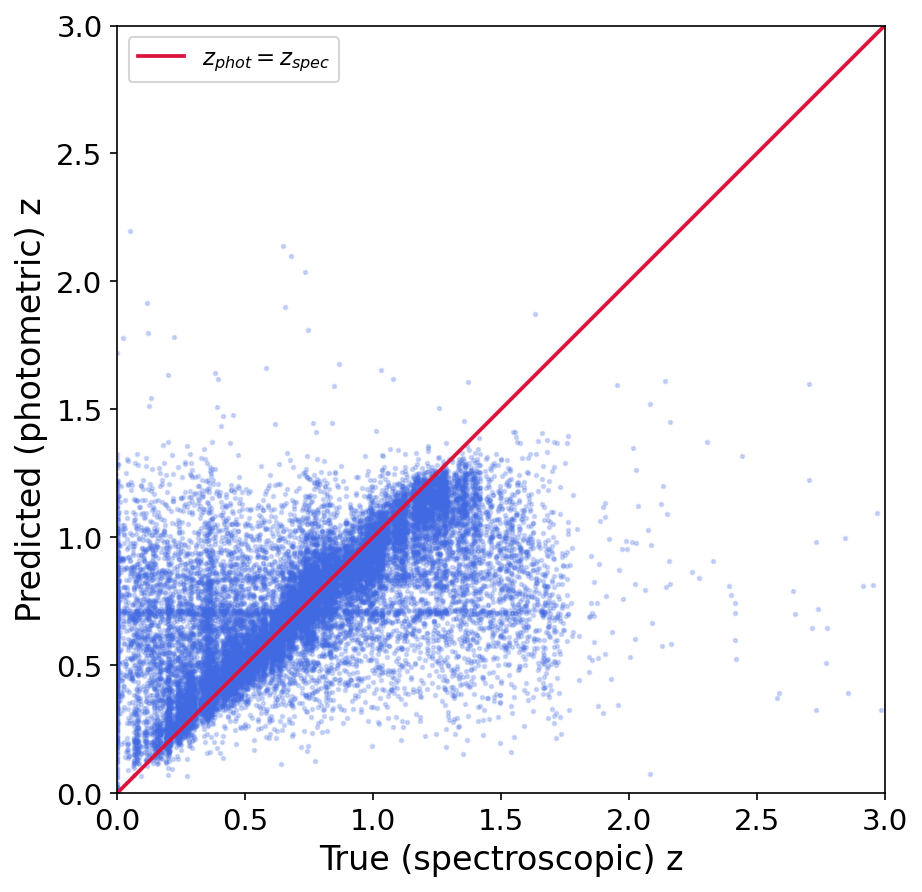

In [19]:
fig, ax = plt.subplots(figsize=(6.4, 6.4))
ax.scatter(target, ypred, s=3, alpha=0.22, color='royalblue', rasterized=True)
ax.plot([0, 3], [0, 3], color='crimson', lw=1.8, label=r'$z_{phot}=z_{spec}$')
ax.set(xlabel='True (spectroscopic) z', ylabel='Predicted (photometric) z',
       xlim=(0, 3), ylim=(0, 3))
ax.set_aspect('equal', adjustable='box')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

Se observa una relación entre el redshift espectroscópico y el predicho, pero con bastante dispersión. El modelo tampoco reproduce tan bien los valores más altos de $z$. Comparado con el paper, nuestro resultado inicial es peor, lo que tiene sentido porque aún no hemos filtrado los datos ni usado los colores como entradas.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

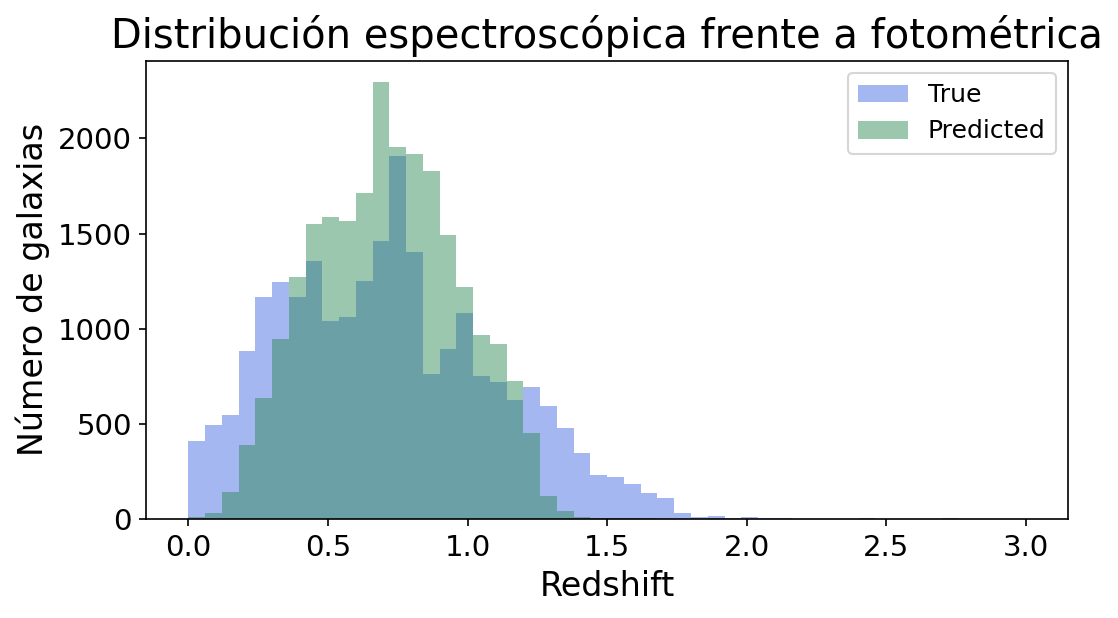

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.hist(target, bins=50, alpha=0.48, range=(0, 3), label='True', color='royalblue')
ax.hist(ypred, bins=50, alpha=0.48, range=(0, 3), label='Predicted', color='seagreen')
ax.set(xlabel='Redshift', ylabel='Número de galaxias',
       title='Distribución espectroscópica frente a fotométrica')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

In [21]:
# Usamos las definiciones indicadas en la guía, y no las métricas de sklearn.
def metricas_photoz(zspec, zphot):
    zspec = np.asarray(zspec, dtype=float)
    zphot = np.asarray(zphot, dtype=float)
    delta = zphot - zspec
    residuo_normalizado = np.abs(delta) / (1.0 + zspec)
    return {
        'R2': r2_score(zspec, zphot),
        'sigma_NMAD': 1.48 * np.median(residuo_normalizado),
        'eta': np.mean(residuo_normalizado > 0.15),
        'n': len(zspec)
    }

metricas_inicial = metricas_photoz(target, ypred)
print('Fracción de outliers (eta): {:.2%}'.format(metricas_inicial['eta']))

Fracción de outliers (eta): 25.71%


In [22]:
n_outliers = np.count_nonzero(np.abs((ypred - target) / (1 + target)) > 0.15)
print(f'Objetos outliers: {n_outliers} de {len(target)}')
print('Criterio: |z_phot - z_spec| / (1 + z_spec) > 0.15')

Objetos outliers: 6124 de 23822
Criterio: |z_phot - z_spec| / (1 + z_spec) > 0.15


y NMAD

In [23]:
print('sigma_NMAD inicial = {:.4f}'.format(metricas_inicial['sigma_NMAD']))
print('Referencias del paper, MAG_APERCOR:')
print('  CFHTLS Deep: sigma_NMAD = 0.018, eta = 4.7% (fig. 6)')
print('  CFHTLS Wide: sigma_NMAD = 0.039, eta = 6.3% (fig. 5)')
print('Comparar estas cifras requiere filtrar las observaciones correctamente.')

sigma_NMAD inicial = 0.0745
Referencias del paper, MAG_APERCOR:
  CFHTLS Deep: sigma_NMAD = 0.018, eta = 4.7% (fig. 6)
  CFHTLS Wide: sigma_NMAD = 0.039, eta = 6.3% (fig. 5)
Comparar estas cifras requiere filtrar las observaciones correctamente.


### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [24]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), size=5000, replace=False)

In [25]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [26]:
seld = features.iloc[sel, :]
selt = target.iloc[sel]
print('Subconjunto de optimización:', seld.shape, selt.shape)

Subconjunto de optimización: (5000, 6) (5000,)


Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [27]:
%%time
littlescores = cross_validate(benchmark_model, seld, selt,
                              cv=cv, return_train_score=True, scoring='r2')

CPU times: user 4.93 s, sys: 106 ms, total: 5.04 s
Wall time: 1.89 s


In [28]:
print('R² de validación con toda la muestra: {:.4f}'.format(scores['test_score'].mean()))
print('R² de validación con 5000 objetos : {:.4f}'.format(littlescores['test_score'].mean()))
print('R² entrenamiento con 5000 objetos : {:.4f}'.format(littlescores['train_score'].mean()))

R² de validación con toda la muestra: 0.3091
R² de validación con 5000 objetos : 0.2731
R² entrenamiento con 5000 objetos : 0.8744


### Optimización de hiperparámetros

Voy a usar `RandomizedSearchCV` con los cinco parámetros pedidos. Como hay muchas combinaciones posibles, probaré 40 con validación cruzada de 3 particiones. Esto permite buscar un modelo mejor sin que el cálculo demore demasiado.

#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [29]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': 3,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [30]:
%%time
parameters = {
    'min_impurity_decrease': [0.0, 0.0001, 0.001, 0.1],
    'max_features': [None, 4, 2],
    'n_estimators': [50, 100, 200],
    'min_samples_split': [2, 10, 20, 100],
    'max_leaf_nodes': [None, 100, 200]
}
# El bosque usa un solo proceso por ajuste y la búsqueda paraleliza hasta 3
# ajustes simultáneos para evitar paralelismo anidado excesivo.
search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=parameters,
    n_iter=40,
    scoring='r2',
    cv=KFold(n_splits=3, shuffle=True, random_state=10),
    return_train_score=True,
    n_jobs=3,
    random_state=42,
    refit=True
)
search.fit(seld, selt)
print('Mejor R² de validación en búsqueda: {:.4f}'.format(search.best_score_))
print('Mejores hiperparámetros:', search.best_params_)

Mejor R² de validación en búsqueda: 0.3015
Mejores hiperparámetros: {'n_estimators': 100, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': None, 'max_features': 4}
CPU times: user 753 ms, sys: 77.5 ms, total: 831 ms
Wall time: 11.8 s


Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [31]:
grid_results = pd.DataFrame(search.cv_results_)
scoresCV = (grid_results[['params', 'mean_test_score',
                          'std_test_score', 'mean_train_score']]
            .sort_values(by='mean_test_score', ascending=False))

In [32]:
scoresCV.head(12)

,params,mean_test_score,std_test_score,mean_train_score
9,"{'n_estimators': 100, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': N...",0.301543,0.004317,0.749286
4,"{'n_estimators': 200, 'min_samples_split': 20, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 2...",0.291399,0.010431,0.606924
32,"{'n_estimators': 100, 'min_samples_split': 10, 'min_impurity_decrease': 0.0001, 'max_leaf_nodes'...",0.290025,0.006941,0.654921
27,"{'n_estimators': 100, 'min_samples_split': 20, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 2...",0.289009,0.011532,0.605590
26,"{'n_estimators': 100, 'min_samples_split': 2, 'min_impurity_decrease': 0.0001, 'max_leaf_nodes':...",0.286611,0.006718,0.776741
31,"{'n_estimators': 50, 'min_samples_split': 10, 'min_impurity_decrease': 0.0001, 'max_leaf_nodes':...",0.282664,0.011878,0.643662
23,"{'n_estimators': 100, 'min_samples_split': 20, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 1...",0.282478,0.010428,0.561161
12,"{'n_estimators': 100, 'min_samples_split': 20, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 1...",0.281399,0.007011,0.550370
8,"{'n_estimators': 50, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 10...",0.276868,0.010296,0.564333
28,"{'n_estimators': 100, 'min_samples_split': 100, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': ...",0.260181,0.010919,0.395647


### ¿Mejoran los resultados?

La búsqueda encuentra una combinación de parámetros con un $R^2$ de validación cercano a 0.30 en la submuestra. Para compararla con el modelo inicial, la evaluamos después sobre el catálogo completo.

In [33]:
%%time
# Probamos el modelo optimizado con las mismas particiones del benchmark.
optimizado = clone(search.best_estimator_)
optimizado.set_params(n_jobs=3)
ypred_optimizado = cross_val_predict(optimizado, features, target, cv=cv)
metricas_optimizado = metricas_photoz(target, ypred_optimizado)
print('Benchmark R²: {:.4f}'.format(metricas_inicial['R2']))
print('Optimizado R²: {:.4f}'.format(metricas_optimizado['R2']))
print('Benchmark NMAD: {:.4f}'.format(metricas_inicial['sigma_NMAD']))
print('Optimizado NMAD: {:.4f}'.format(metricas_optimizado['sigma_NMAD']))
print('Benchmark eta: {:.2%}'.format(metricas_inicial['eta']))
print('Optimizado eta: {:.2%}'.format(metricas_optimizado['eta']))

Benchmark R²: 0.3090
Optimizado R²: 0.3222
Benchmark NMAD: 0.0745
Optimizado NMAD: 0.0769
Benchmark eta: 25.71%
Optimizado eta: 25.87%
CPU times: user 20.3 s, sys: 157 ms, total: 20.5 s
Wall time: 7.06 s


El $R^2$ sube un poco, de **0.3090 a 0.3222**. Sin embargo, $\sigma_{NMAD}$ y la fracción de outliers empeoran ligeramente. Por lo tanto, la optimización de parámetros no produce una mejora. Es mejor revisar primero la calidad de los datos.

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [34]:
mags = df[BANDAS + ['subaru_source', 'cfhtls_source', 'zquality']].copy()

In [35]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [36]:
mags.shape

(23822, 9)

In [37]:
# zquality >= 3: redshift espectroscópico de buena calidad.
mags = mags.loc[mags['zquality'] >= 3].copy()
print('Con zquality >= 3:', mags.shape)

Con zquality >= 3: (16857, 9)


In [38]:
# cfhtls_source == 0: catálogo fotométrico profundo (CFHTLS Deep).
mags = mags.loc[mags['cfhtls_source'] == 0].copy()
print('Con cfhtls_source == 0:', mags.shape)

Con cfhtls_source == 0: (10671, 9)


In [39]:
print('Cantidad de fotometrías fuera del intervalo útil:')
print(((mags[BANDAS] <= -10) | (mags[BANDAS] >= 90)).sum())

Cantidad de fotometrías fuera del intervalo útil:
u_apercor     115
g_apercor     112
r_apercor     111
i_apercor     111
z_apercor     111
y_apercor    4301
dtype: int64


Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [40]:
# Eliminamos datos marcados con -99 (también filtramos NaN).
mags = mags.loc[(mags[BANDAS] > -10).all(axis=1)].dropna()

In [41]:
mags.shape

(6371, 9)

In [42]:
# Eliminamos los marcados con 99.
mags = mags.loc[(mags[BANDAS] < 90).all(axis=1)].dropna()

In [43]:
mags.shape

(6307, 9)

Después de aplicar los filtros quedan **6307 objetos** con mediciones válidas en las seis bandas. Las columnas `zquality` y `cfhtls_source` se usaron solamente para seleccionar los datos, no como variables de entrada del modelo.

In [44]:
sel_features = mags[BANDAS].copy()
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [45]:
sel_target = target.loc[sel_features.index].copy()
assert sel_features.index.equals(sel_target.index)
print('X limpio:', sel_features.shape, '| y limpio:', sel_target.shape)

X limpio: (6307, 6) | y limpio: (6307,)


**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

In [46]:
%%time
scores_new = cross_validate(benchmark_model, sel_features, sel_target,
                            cv=cv, scoring='r2', return_train_score=True)

CPU times: user 6.65 s, sys: 74.5 ms, total: 6.72 s
Wall time: 2.43 s


In [47]:
resumen_filtrado = pd.DataFrame({
    'R² train medio': [scores['train_score'].mean(), scores_new['train_score'].mean()],
    'R² test medio': [scores['test_score'].mean(), scores_new['test_score'].mean()],
    'desv. R² test': [scores['test_score'].std(), scores_new['test_score'].std()],
    'n objetos': [len(target), len(sel_target)]
}, index=['Sin filtrar', 'Calidad + seis bandas'])
resumen_filtrado.round(4)

,R² train medio,R² test medio,desv. R² test,n objetos
Sin filtrar,0.8756,0.3091,0.0054,23822
Calidad + seis bandas,0.9635,0.7441,0.1014,6307


In [48]:
%%time
ypred_new = cross_val_predict(benchmark_model, sel_features, sel_target, cv=cv)
metricas_filtrado = metricas_photoz(sel_target, ypred_new)
print('Métricas con la selección de calidad:')
for k, v in metricas_filtrado.items():
    print(f'  {k}: {v:.4f}' if k != 'n' else f'  n: {v}')

Métricas con la selección de calidad:
  R2: 0.7366
  sigma_NMAD: 0.0355
  eta: 0.0557
  n: 6307
CPU times: user 6.68 s, sys: 89.7 ms, total: 6.77 s
Wall time: 2.48 s


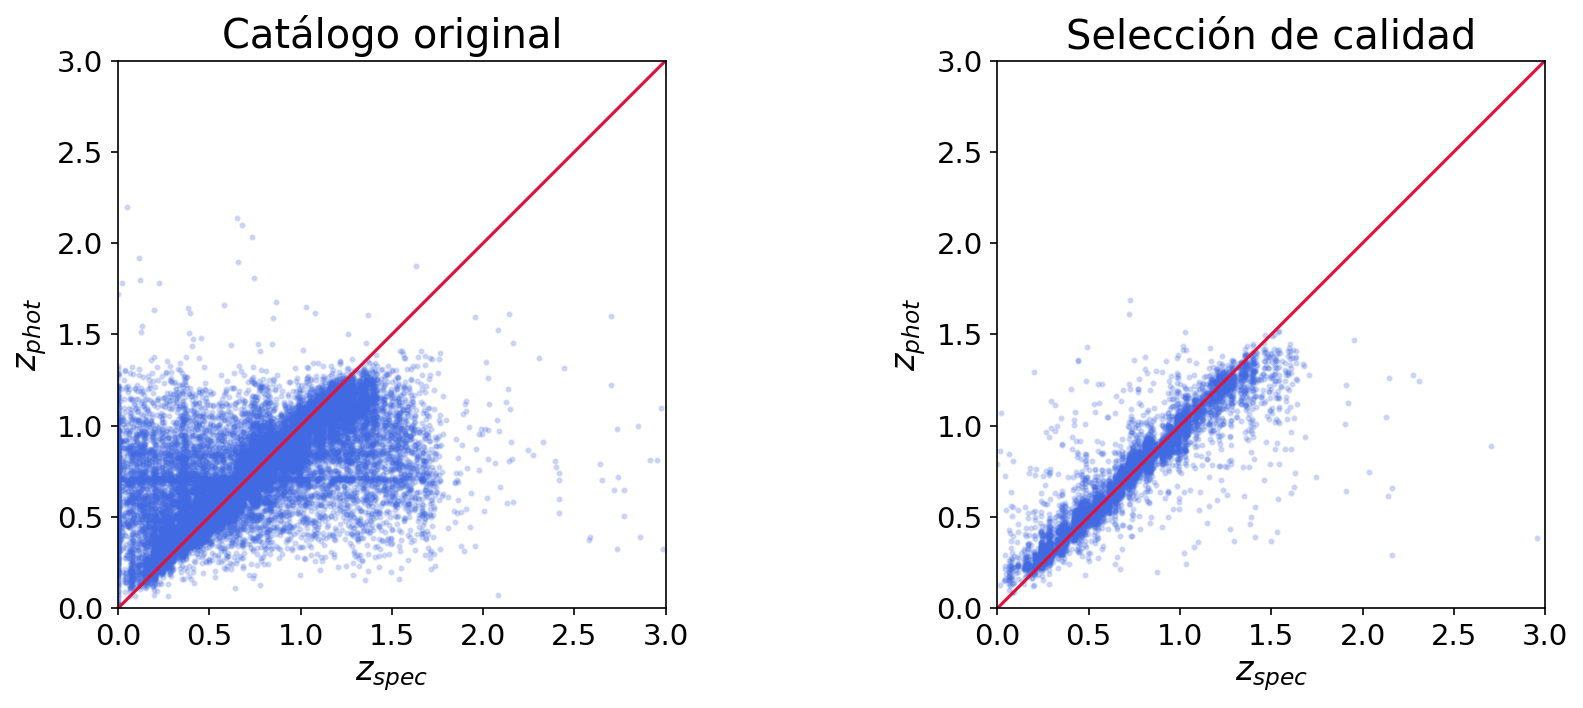

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, verdad, predic, titulo in [
    (ax[0], target, ypred, 'Catálogo original'),
    (ax[1], sel_target, ypred_new, 'Selección de calidad')]:
    a.scatter(verdad, predic, s=4, alpha=0.2, c='royalblue', rasterized=True)
    a.plot([0, 3], [0, 3], c='crimson', lw=1.5)
    a.set(xlim=(0, 3), ylim=(0, 3), title=titulo,
          xlabel=r'$z_{spec}$', ylabel=r'$z_{phot}$')
    a.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

### Comparación con el paper

Con los datos filtrados, el modelo mejora bastante: obtenemos $R^2=0.737$, $\sigma_{NMAD}=0.0355$ y **5.57 % de outliers**. Es un resultado mucho mejor que con el catálogo completo, aunque la dispersión todavía es mayor que la reportada por Zhou et al. (2019) para CFHTLS Deep ($\sigma_{NMAD}=0.018$ y $\eta=4.7\%$).

### Mejora propuesta en la sección 7 del paper

En el artículo no se usan directamente las seis magnitudes, sino **cinco colores** ($u-g$, $g-r$, $r-i$, $i-z$, $z-y$) y la magnitud $i$. Los colores muestran cómo cambia el brillo entre filtros y pueden ayudar a estimar mejor el redshift.

Voy a probar esas variables con los mismos 6307 objetos y las mismas particiones para comparar los resultados.

Referencia: [Zhou et al. (2019), sección 7](https://doi.org/10.1093/mnras/stz1866).

El catálogo seleccionado corresponde a **CFHTLS Deep**, así que la comparación del artículo es con la **figura 6**. La figura 5 muestra CFHTLS Wide.

In [50]:
def crear_colores(tabla):
    """Cinco colores adyacentes más magnitud i, como en Zhou et al. (2019)."""
    return pd.DataFrame({
        'u-g': tabla['u_apercor'] - tabla['g_apercor'],
        'g-r': tabla['g_apercor'] - tabla['r_apercor'],
        'r-i': tabla['r_apercor'] - tabla['i_apercor'],
        'i-z': tabla['i_apercor'] - tabla['z_apercor'],
        'z-y': tabla['z_apercor'] - tabla['y_apercor'],
        'i': tabla['i_apercor']
    }, index=tabla.index)

colores = crear_colores(sel_features)
display(colores.head())
print('Muestra y número de features:', colores.shape)

,u-g,g-r,r-i,i-z,z-y,i
1251,0.264811,0.457447,0.611094,0.385268,0.196675,22.911041
1253,0.572953,0.992500,1.049899,0.567258,0.055055,21.873752
1261,1.900066,1.508042,0.677430,0.326138,0.048586,20.788420
1271,0.190411,0.447442,0.685087,0.216758,-0.123037,23.206102
1272,0.253733,0.412146,0.740102,0.425541,0.250175,22.235199


Muestra y número de features: (6307, 6)


In [51]:
%%time
scores_colores = cross_validate(benchmark_model, colores, sel_target,
                                cv=cv, scoring='r2', return_train_score=True)
ypred_colores = cross_val_predict(benchmark_model, colores, sel_target, cv=cv)
metricas_colores = metricas_photoz(sel_target, ypred_colores)
print('R² test medio (magnitudes): {:.4f}'.format(scores_new['test_score'].mean()))
print('R² test medio (colores + i): {:.4f}'.format(scores_colores['test_score'].mean()))

R² test medio (magnitudes): 0.7441
R² test medio (colores + i): 0.8084
CPU times: user 14.1 s, sys: 171 ms, total: 14.3 s
Wall time: 5.16 s


### Comparación final

In [52]:
comparacion = pd.DataFrame.from_dict({
    'Inicial (23 822)': metricas_inicial,
    'Limpio: 6 magnitudes': metricas_filtrado,
    'Limpio: 5 colores + i': metricas_colores,
    'Optimizado: datos brutos': metricas_optimizado
}, orient='index')
comparacion['eta (%)'] = 100 * comparacion.pop('eta')
display(comparacion[['n', 'R2', 'sigma_NMAD', 'eta (%)']].round(4))
print('Paper CFHTLS Deep (fig. 6): NMAD=0.018, eta=4.7%')
print('Paper CFHTLS Wide (fig. 5): NMAD=0.039, eta=6.3%')

,n,R2,sigma_NMAD,eta (%)
Inicial (23 822),23822,0.3090,0.0745,25.7073
Limpio: 6 magnitudes,6307,0.7366,0.0355,5.5652
Limpio: 5 colores + i,6307,0.8024,0.0166,3.5358
Optimizado: datos brutos,23822,0.3222,0.0769,25.8710


Paper CFHTLS Deep (fig. 6): NMAD=0.018, eta=4.7%
Paper CFHTLS Wide (fig. 5): NMAD=0.039, eta=6.3%


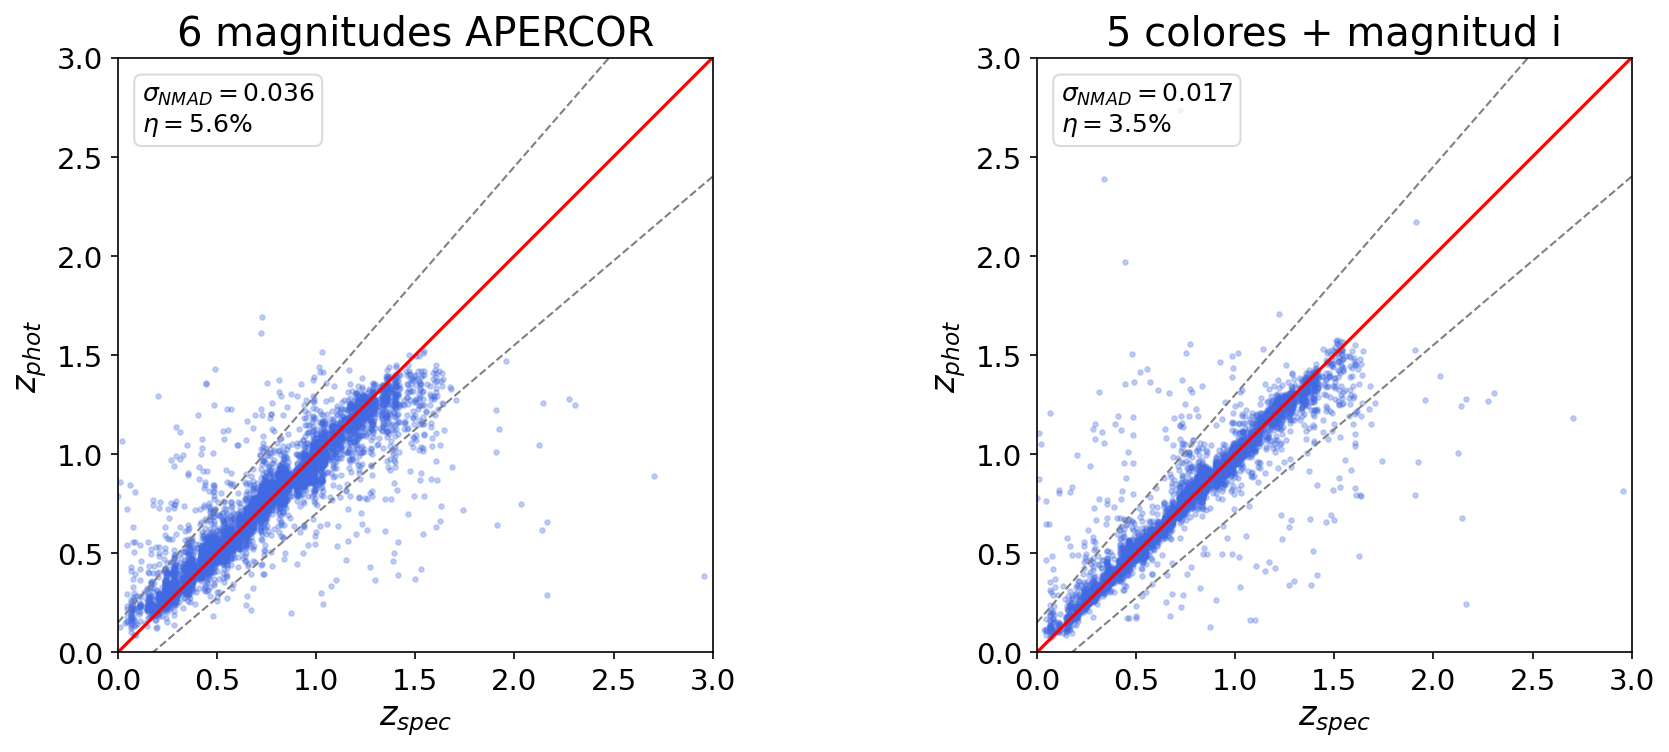

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.3))
for ax, y, titulo, met in [
    (axes[0], ypred_new, '6 magnitudes APERCOR', metricas_filtrado),
    (axes[1], ypred_colores, '5 colores + magnitud i', metricas_colores)]:
    z = np.asarray(sel_target)
    ax.scatter(z, y, s=5, alpha=.28, c='royalblue', rasterized=True)
    zz = np.linspace(0, 3, 120)
    ax.plot(zz, zz, 'r-', lw=1.5)
    ax.plot(zz, zz + 0.15*(1+zz), '--', color='gray', lw=1)
    ax.plot(zz, zz - 0.15*(1+zz), '--', color='gray', lw=1)
    ax.set(xlim=(0, 3), ylim=(0, 3), xlabel=r'$z_{spec}$',
           ylabel=r'$z_{phot}$', title=titulo)
    ax.text(.04, .96, rf'$\sigma_{{NMAD}}={met["sigma_NMAD"]:.3f}$' + '\n' +
            rf'$\eta={100*met["eta"]:.1f}\%$',
            transform=ax.transAxes, va='top', fontsize=12,
            bbox=dict(boxstyle='round', fc='white', alpha=.8, ec='lightgray'))
    ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

### Conclusión

El cambio más importante fue filtrar las mediciones que no eran válidas y trabajar con redshifts espectroscópicos de buena calidad. Esto redujo bastante la dispersión y la cantidad de outliers.

Al usar los cinco colores más la magnitud $i$, el resultado mejora otra vez: $R^2=0.802$, $\sigma_{NMAD}=0.0166$ y 3.54 % de outliers. Son valores cercanos a los del paper e incluso un poco mejores para estas métricas, aunque no podemos decir que reproducimos exactamente su análisis porque las muestras y los detalles del modelo pueden ser diferentes.

En general, la selección de datos y las variables utilizadas influyeron más que el ajuste de hiperparámetros. También se ve que las predicciones tienen mayor dispersión en los redshifts altos, donde hay menos objetos de entrenamiento.